Python Data Cleaning and Visualization - 10/14/2026 - jaybat1453

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

#Load your original Excel spreadsheet
df = pd.read_excel("AirBnBSummary_v2.xlsx")

# Display the first five rows
display(df.head())

# Check column names and data types
print(df.info())

,id,host_id,host_name,neighbourhood,room_type,price,minimum_nights,number_of_reviews,availability_365,<StudentID>
0,7909479,41706311,David,Downtown,Entire home/apt,107.0,30,27,365.0,NaN
1,15966488,103700433,Erin,Downtown,Entire home/apt,100.0,1,250,74.0,NaN
2,19859814,103700433,Erin,Downtown,Entire home/apt,100.0,1,309,79.0,NaN
3,21071138,22992627,Joseph,Downtown,Entire home/apt,100.0,2,144,338.0,NaN
4,21712505,103700433,Erin,Downtown,Entire home/apt,100.0,1,178,68.0,NaN


<class 'pandas.DataFrame'>
RangeIndex: 1779 entries, 0 to 1778
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 1779 non-null   int64  
 1   host_id            1779 non-null   int64  
 2   host_name          1779 non-null   str    
 3   neighbourhood      1779 non-null   str    
 4   room_type          1779 non-null   str    
 5   price              1775 non-null   float64
 6   minimum_nights     1779 non-null   int64  
 7   number_of_reviews  1779 non-null   int64  
 8   availability_365   1774 non-null   float64
 9   <StudentID>        0 non-null      float64
dtypes: float64(3), int64(4), str(3)
memory usage: 139.1 KB
None


In [2]:
# Remove duplicate rows 
df = df.drop_duplicates()

# Correct room type capitalization
df["room_type"] = df["room_type"].replace("Private room", "Private Room")

# Check the room type
print(df["room_type"].value_counts())

room_type
Entire home/apt    1535
Private Room        240
Name: count, dtype: int64


In [3]:
# Fill missing numerical values with each column's median
numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missig text values with each column's mode
for col in df.select_dtypes(include="object").columns:
    if df[col].isnull().any() and not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])

# check for remaining missing values
print(df.isnull().sum())

id                      0
host_id                 0
host_name               0
neighbourhood           0
room_type               0
price                   0
minimum_nights          0
number_of_reviews       0
availability_365        0
<StudentID>          1775
dtype: int64


C:\Users\Student\AppData\Local\Temp\ipykernel_7252\2736736200.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


In [4]:
# Columns to check for outliers
outlier_cols = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "availability_365"
]

# Calculate the IQR limits for each column
outlier_mask = pd.Series(True, index=df.index)

for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask &= df[col].between(lower_bound, upper_bound)

    # keep rows that are not outliers
    df = df[outlier_mask].copy()

    print("Rows remaining after removing outliers:", len(df))

Rows remaining after removing outliers: 1657
Rows remaining after removing outliers: 1369
Rows remaining after removing outliers: 1239
Rows remaining after removing outliers: 1239


C:\Users\Student\AppData\Local\Temp\ipykernel_7252\1752757553.py:23: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df = df[outlier_mask].copy()
C:\Users\Student\AppData\Local\Temp\ipykernel_7252\1752757553.py:23: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df = df[outlier_mask].copy()
C:\Users\Student\AppData\Local\Temp\ipykernel_7252\1752757553.py:23: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df = df[outlier_mask].copy()


In [5]:
df.to_excel("AirBnBSummRY_v2_Python_Cleaned.xlsx", index=False)

print("Cleaned data saved succesfully.")

Cleaned data saved succesfully.


In [6]:
print("Total count of listings:", df.shape[0]) 
print("Minimum price:", df["price"].min()) 
print("Maximum price:", df["price"].max()) 
print("Mean price of listings:", df["price"].mean()) 
print("Median number_of_reviews:", df["number_of_reviews"].median()) 
print("Mode of minimum_nights:", df["minimum_nights"].mode().tolist()) 
print("Standard deviation of price:", df["price"].std()) 
print("Correlation between price and availability_365:", df["price"].corr(df["availability_365"]) 

) 

Total count of listings: 1239
Minimum price: 32.0
Maximum price: 308.0
Mean price of listings: 132.42857142857142
Median number_of_reviews: 21.0
Mode of minimum_nights: [1]
Standard deviation of price: 62.409646668047685
Correlation between price and availability_365: 0.09767245523722262


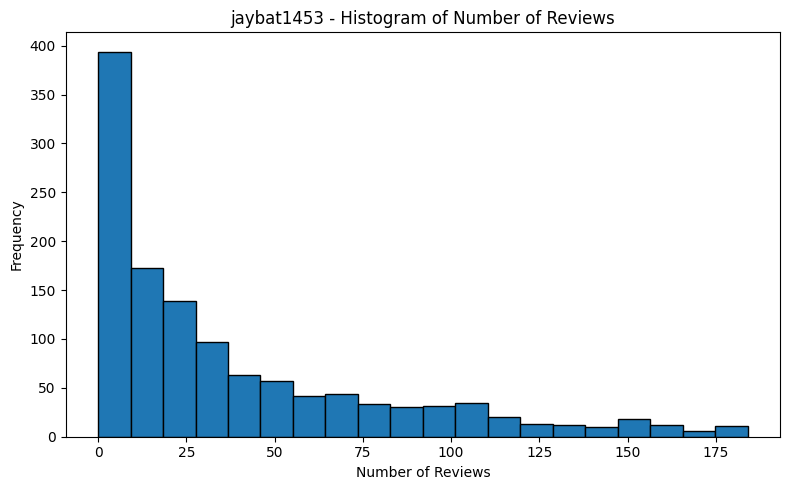

In [7]:
plt.figure(figsize=(8, 5)) 
plt.hist(df["number_of_reviews"], bins=20, edgecolor="black") 
plt.title("jaybat1453 - Histogram of Number of Reviews") 
plt.xlabel("Number of Reviews") 
plt.ylabel("Frequency") 
plt.tight_layout() 
plt.show() 

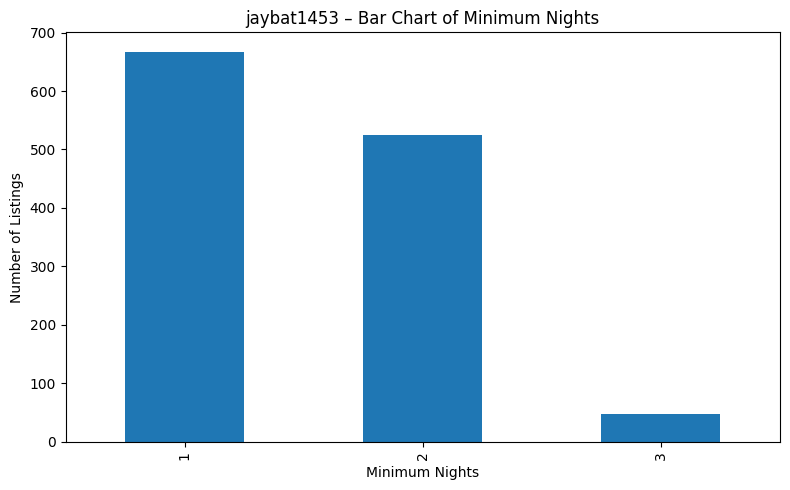

In [8]:
plt.figure(figsize=(8, 5)) 

df["minimum_nights"].value_counts().sort_index().head(20).plot( 

    kind="bar" 

) 

plt.title("jaybat1453 – Bar Chart of Minimum Nights") 
plt.xlabel("Minimum Nights") 
plt.ylabel("Number of Listings") 
plt.tight_layout() 
plt.show() 

 

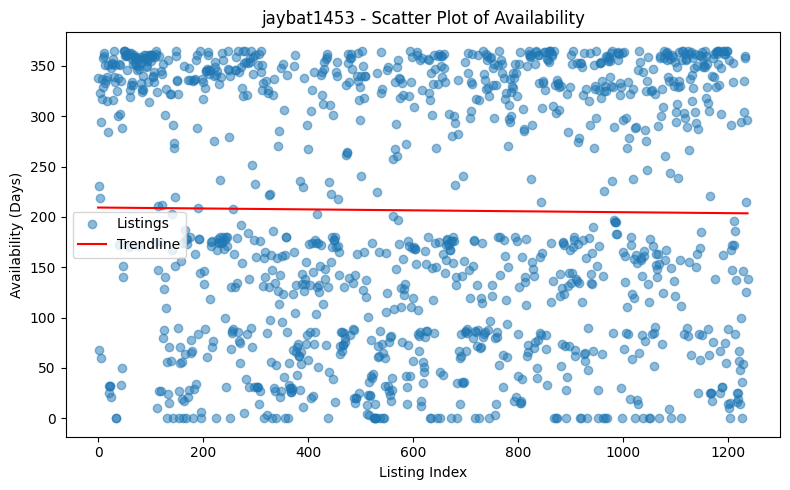

In [9]:
plt.figure(figsize=(8, 5)) 

x = np.arange(len(df)) 
y = df["availability_365"].values 


plt.scatter(x, y, alpha=0.5, label="Listings") 

# Add trendline 
slope, intercept = np.polyfit(x, y, 1) 

plt.plot(x, slope * x + intercept, color="red", label="Trendline") 

plt.title("jaybat1453 - Scatter Plot of Availability") 
plt.xlabel("Listing Index") 
plt.ylabel("Availability (Days)") 
plt.legend() 
plt.tight_layout() 
plt.show() 

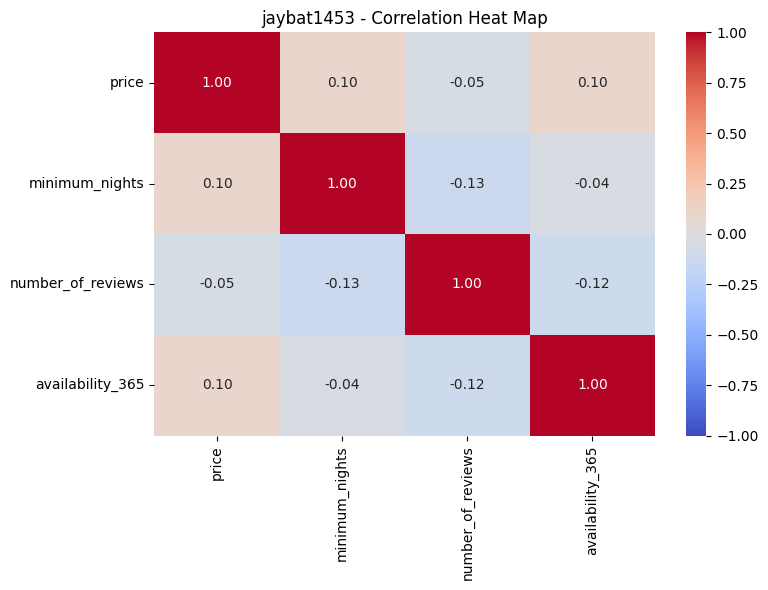

In [10]:
corr_cols = [ 

    "price", 
    "minimum_nights", 
    "number_of_reviews", 
    "availability_365" 

] 

 
correlation_matrix = df[corr_cols].corr() 

 
plt.figure(figsize=(8, 6)) 

sns.heatmap( 

    correlation_matrix, 
    annot=True, 
    cmap="coolwarm", 
    vmin=-1, 
    vmax=1, 
    fmt=".2f" 

) 

plt.title("jaybat1453 - Correlation Heat Map") 
plt.tight_layout() 
plt.show()